<div style="border-top:5px solid #173c63; padding:20px 0 15px 0; max-width:950px">
  <div style="color:#687e96;letter-spacing:0.13em;font-size:12px;font-weight:700">DIGITAL COMMUNICATIONS · CHAPTER 3 · REPRODUCIBLE NOTEBOOK</div>
  <h1 style="margin:10px 0 10px 0;font-size:31px">3.6.4 Examples Revisited</h1>
  <div style="font-size:19px;color:#396087">MMSE-DFE and Zero-Forcing DFE · PAM &amp; QAM</div>
  <div style="font-size:13px;color:#657385;margin-top:13px">Mathematical derivations · Canonical spectral factorization · Python reference model · Verification</div>
</div>

> **Abstract.** This notebook reproduces **Example 3.6.1 (real-valued two-tap PAM)** and **Example 3.6.2 (complex-valued three-tap QAM)** from Cioffi, *Digital Communications*, §3.6.4. For each example, we derive the channel energy, matched-filter autocorrelation, regularized spectrum, minimum-phase canonical factors, MMSE/ZF feedforward and feedback filters, and biased/unbiased detection SNRs. Every result is verified numerically using the previously implemented `adsp.equalization.MMSEDFE` and `ZFDFE` reference models.

**Presentation style:** The chapter outline, mathematical exposition, figures, and executable code follow the technical-article presentation style of [A Fix for Softmax and Cross-Entropy](https://jonbarron.info/softmaxfix/); the DFE mathematics and numerical examples come from Cioffi §3.6.4 and are **unrelated to the research claims of the Softmax article**.

**Source:** J. M. Cioffi, *Digital Communications*, [Chapter 3](https://cioffi-group.stanford.edu/doc/book/chap3.pdf), §§3.6.1–3.6.4. Notebook conventions: 2-space indentation, approximately 120-column source lines, section-based Markdown, and in-place executable outputs.

## Contents

1. [Notation and normalization](#1-notation-and-normalization)
2. [Setup and reference-model interface](#2-setup-and-reference-model-interface)
3. [Example 3.6.1 — PAM-DFE](#3-example-361--pam-dfe)
4. [Example 3.6.2 — QAM-DFE](#4-example-362--qam-dfe)
5. [Whitening and bias-removal identities](#5-whitening-and-bias-removal-identities)
6. [Monte Carlo: correct feedback versus decision-directed](#6-monte-carlo-correct-feedback-versus-decision-directed)
7. [Finite feedforward approximation](#7-finite-feedforward-approximation)
8. [Comparative results and conclusions](#8-comparative-results-and-conclusions)

---

## 1. Notation and normalization

To prevent confusion among different SNR definitions, filter coefficients, and noise variances, we preserve the textbook notation and do not introduce shorthand for frequency averages or SNR quantities.

| Quantity | Definition | Meaning |
|:--|:--|:--|
| $D$ | $z^{-1}$ | Delay operator for one symbol period |
| $T$ | $1$ | Symbol period, normalized to unity in this notebook |
| $\bar E_x$ | $1$ (per real dimension) | PAM has $\mathbb E[x_k^2]=1$; QAM has $\mathbb E[|x_k|^2]=2$ |
| $Q(D)$ | $\sum_m q_mD^m$ | Normalized matched-filter autocorrelation, with $q_0=1$ |
| $\|h\|^2$ | $\sum_m |h_m|^2$ | channel pulse energy |
| $N_0/2$ | $\bar E_x\|h\|^2/SNR_{\rm MFB}$ | Noise parameter per real dimension |
| $G(D),\gamma_0$ | $Q+1/SNR_{\rm MFB}=\gamma_0 GG^\sharp$ | MMSE canonical factors |
| $P_c(D),\eta_0$ | $Q=\eta_0P_cP_c^\sharp$ | ZF canonical factors |

**Complex conjugation:** We use $F^\sharp(D)\equiv F^*(D^{-*})$ as a convenient notation for the *paraconjugate*. This notation is introduced for explanation in this notebook; it is not an additional symbol defined by Cioffi. For

$$F(D)=f_0+f_1D+f_2D^2,\qquad F^\sharp(D)=f_0^*+f_1^*D^{-1}+f_2^*D^{-2}.$$

Matched-filter output model：

$$
Y(D)=\|h\|Q(D)X(D)+N(D),\qquad
\bar R_{nn}(D)=\frac{N_0}{2}Q(D),\qquad
SNR_{\rm MFB}=\frac{\bar E_x\|h\|^2}{N_0/2}.
$$

**Two DFE realizations:**

$$
\begin{aligned}
\text{MMSE: }&\; W(D)=\frac{1}{\|h\|\gamma_0G^\sharp(D)},\quad
B(D)=G(D),\quad\alpha=1-\frac{1}{\gamma_0SNR_{\rm MFB}},\\[3pt]
\text{ZF: }&\;W(D)=\frac{1}{\|h\|\eta_0P_c^\sharp(D)},\quad
B(D)=P_c(D),\quad\alpha=1.
\end{aligned}
$$

**The physical feedback filter is always $1-B(D)$, not $B(D)$ itself.** For MMSE-DFE, the biased decision input is $Z'(D)$. The unbiased output $Z'_U(D)=Z'(D)/\alpha$ can be passed to a slicer using the original constellation.

## 2. Setup and reference-model interface

This notebook imports the existing `MMSEDFE` and `ZFDFE` implementations from `adsp.equalization.canonical_dfe`; **it does not reimplement spectral factorization inside the notebook**. As in `09_fse_passband_nyquist_inband.ipynb`, the setup searches upward from the working directory for the repository root containing `adsp`.

- In the repository: place the notebook under `notebooks/` and ensure `adsp/equalization/canonical_dfe.py` is installed.
- In the standalone bundle: `adsp/` contains the required reference-model modules, so the notebook can run without additional project files.
- `n_taps` specifies a finite truncation of the ideal anticausal feedforward response; it is **not** the optimal finite-length FIR solution of Chapter 3.7.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

project_root = next(
  (path for path in [Path.cwd(), *Path.cwd().parents]
   if (path / "adsp" / "equalization" / "canonical_dfe.py").is_file()),
  None,
)
if project_root is None:
  raise FileNotFoundError("Cannot locate adsp/equalization/canonical_dfe.py from the notebook directory.")
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp.equalization.canonical_dfe import MMSEDFE, ZFDFE

SNR_MFB = 10.0                   # 10 dB, linear power ratio
SYMBOL_ENERGY_PER_REAL = 1.0    # E_x in Cioffi's convention
N_FFT = 32768
N_FF = 160
RNG_SEED = 3642026

plt.rcParams.update({
  "figure.figsize": (9.0, 3.6),
  "figure.dpi": 105,
  "axes.grid": True,
  "grid.alpha": 0.23,
  "axes.spines.top": False,
  "axes.spines.right": False,
  "font.size": 10,
})
print("Project root:", project_root)
print(f"SNR_MFB = {SNR_MFB:.6f} (linear) = {10 * np.log10(SNR_MFB):.1f} dB")

Project root: /pysim
SNR_MFB = 10.000000 (linear) = 10.0 dB


In [2]:
def complexText(value: complex, digits: int = 8) -> str:
  """Readable complex coefficients for printed tables."""
  value = complex(value)
  if abs(value.imag) < 1e-12:
    return f"{value.real:.{digits}f}"
  return f"{value.real:.{digits}f} {value.imag:+.{digits}f}j"


def coefficientTable(indices, values, label="Coefficient") -> pd.DataFrame:
  return pd.DataFrame({
    "Lag / degree": np.asarray(indices, dtype=int),
    label: [complexText(value) for value in values],
  })


def fftOfIndexedTaps(taps, indices, n_fft: int) -> np.ndarray:
  """Evaluate sum_m taps[m] exp(-j 2*pi*k*m/N) on a unit-circle FFT grid."""
  periodic = np.zeros(n_fft, dtype=np.complex128)
  np.add.at(periodic, np.mod(np.asarray(indices, dtype=int), n_fft), taps)
  return np.fft.fft(periodic)


def buildDfePair(channel, constellation):
  args = dict(snr_mfb=SNR_MFB, n_taps=N_FF, n_fft=N_FFT, constellation=constellation)
  return MMSEDFE.fromChannel(channel, **args), ZFDFE.fromChannel(channel, **args)


def checkCanonical(model) -> float:
  """Independent reconstruction using the explicitly stored polynomial taps."""
  canonical = fftOfIndexedTaps(
    model.canonical_factor, np.arange(len(model.canonical_factor)), model.n_fft,
  )
  regularization = 1.0 / model.snr_mfb if model.criterion == "mmse" else 0.0
  residual = model._q_bins + regularization - model.factor_scale * abs(canonical)**2
  return float(np.max(abs(residual)))


def positiveDb(value: float) -> float:
  return float(10.0 * np.log10(value))

## 3. Example 3.6.1 — PAM-DFE

### 3.1 Channel response and autocorrelation — Eq. (3.270)

The textbook considers the following real-valued two-tap PAM channel:

$$H(\omega)=\sqrt T\left(1+0.9e^{j\omega T}\right),\qquad |\omega|\le\frac{\pi}{T}.$$

Because reversing the entire channel in time leaves its magnitude spectrum unchanged, the numerical model uses the corresponding sampled coefficients $h=[1,\;0.9]$. The channel energy is:

$$
\|h\|^2=|1|^2+|0.9|^2=1+0.81=\boxed{1.81}.
$$

With a matched-filter bound of $10\,\mathrm{dB}$, the noise parameter is:

$$
\frac{N_0}{2}=\frac{\bar E_x\|h\|^2}{SNR_{\rm MFB}}
=\frac{1\times1.81}{10}=\boxed{0.181}.
$$

The autocorrelation coefficients are $r_{hh}[0]=1.81$ and $r_{hh}[1]=r_{hh}[-1]=0.9$. Consequently,

$$
\begin{aligned}
Q(D)&=\frac{0.9D^{-1}+1.81+0.9D}{1.81}\\
&=\boxed{1+\frac{0.9}{1.81}(D+D^{-1})}.
\end{aligned}
$$

On the unit circle, with $D=e^{-j\omega T}$:

$$
Q(e^{-j\omega T})=\frac{1.81+1.8\cos(\omega T)}{1.81},\qquad
Q(e^{-j\pi})=\frac{0.01}{1.81}.
$$

The deep spectral notch near the Nyquist frequency causes substantial noise enhancement when the ZF-LE inverts the channel spectrum.

||h||^2 = 1.810000000, ||h|| = 1.345362405, N0/2 = 0.181000000


,Lag / degree,q[m]
0,-1,0.49723757
1,0,1.00000000
2,1,0.49723757


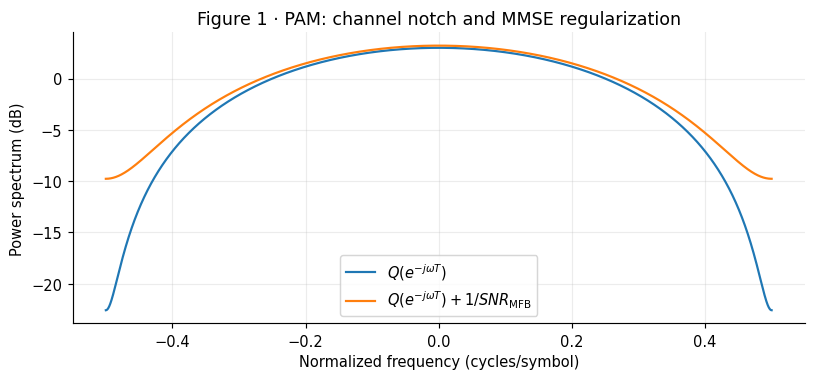

In [3]:
pam_h = np.array([1.0, 0.9], dtype=np.complex128)
pam_constellation = np.array([-1.0, 1.0], dtype=np.complex128)
pam_mmse, pam_zf = buildDfePair(pam_h, pam_constellation)
pam_energy = float(np.vdot(pam_h, pam_h).real)
pam_noise_var = SYMBOL_ENERGY_PER_REAL * pam_energy / SNR_MFB

print(f"||h||^2 = {pam_energy:.9f}, ||h|| = {np.sqrt(pam_energy):.9f}, N0/2 = {pam_noise_var:.9f}")
display(coefficientTable(pam_mmse.q_index, pam_mmse.q, "q[m]"))
assert np.isclose(pam_energy, 1.81)
assert np.allclose(pam_mmse.q, np.array([0.9, 1.81, 0.9]) / 1.81)

freq = np.fft.fftshift(np.fft.fftfreq(N_FFT))
pam_q_freq = np.fft.fftshift(pam_mmse._q_bins)
fig, ax = plt.subplots()
ax.plot(freq, 10 * np.log10(pam_q_freq), label=r"$Q(e^{-j\omega T})$")
ax.plot(freq, 10 * np.log10(pam_q_freq + 1 / SNR_MFB),
        label=r"$Q(e^{-j\omega T})+1/SNR_{\rm MFB}$")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Power spectrum (dB)",
       title="Figure 1 · PAM: channel notch and MMSE regularization")
ax.legend()
plt.show()

### 3.2 MMSE canonical factorization — Eq. (3.271)–(3.274)

The regularized spectrum explicitly includes $SNR_{\rm MFB}=10$:

$$
\begin{aligned}
Q(D)+\frac{1}{SNR_{\rm MFB}}
&=\frac{0.9D+1.81+0.9D^{-1}}{1.81}+0.1\\
&=\boxed{\frac{0.9D+1.991+0.9D^{-1}}{1.81}}.
\end{aligned}
$$

Since the autocorrelation has maximum positive lag $1$, choose a monic first-order factor $G(D)=1+g_1D$ and write

$$
Q(D)+\frac1{SNR_{\rm MFB}}=\gamma_0(1+g_1D)(1+g_1D^{-1}).
$$

Match the constant and $D^1$ coefficients:

$$
\gamma_0(1+g_1^2)=\frac{1.991}{1.81}=1.1,
\qquad \gamma_0 g_1=\frac{0.9}{1.81}.
$$

Eliminate $g_1$:

$$
\gamma_0^2-1.1\gamma_0+\left(\frac{0.9}{1.81}\right)^2=0,
\qquad
\gamma_0=\frac{1.1\pm\sqrt{1.1^2-4(0.9/1.81)^2}}{2}.
$$

Both algebraic solutions reconstruct the same power spectrum. **Select the solution satisfying $|g_1|<1$**: the zero of $G(z)=1+g_1z^{-1}$ is at $z=-g_1$, and the minimum-phase condition requires $|z|<1$.

In [4]:
pam_q1 = 0.9 / 1.81
pam_discriminant = 1.1**2 - 4 * pam_q1**2
pam_candidates = [(1.1 + np.sqrt(pam_discriminant)) / 2,
                  (1.1 - np.sqrt(pam_discriminant)) / 2]
pam_root_rows = []
for gamma0_candidate in pam_candidates:
  g1_candidate = pam_q1 / gamma0_candidate
  pam_root_rows.append({
    "gamma0 candidate": gamma0_candidate,
    "g1 candidate": g1_candidate,
    "zero z = -g1": -g1_candidate,
    "minimum-phase?": abs(g1_candidate) < 1.0,
  })
display(pd.DataFrame(pam_root_rows).round(9))

pam_gamma0_closed = next(value for value in pam_candidates if abs(pam_q1 / value) < 1.0)
pam_g1_closed = pam_q1 / pam_gamma0_closed
assert np.isclose(pam_mmse.gamma0, pam_gamma0_closed, atol=1e-10)
assert np.isclose(pam_mmse.canonical_factor[1], pam_g1_closed, atol=1e-10)
assert checkCanonical(pam_mmse) < 1e-10

print(f"Selected gamma_0 = {pam_mmse.gamma0:.10f}")
print(f"Selected G(D) = 1 + ({complexText(pam_mmse.canonical_factor[1], 10)}) D")
print(f"Maximum canonical reconstruction residual = {checkCanonical(pam_mmse):.3e}")

,gamma0 candidate,g1 candidate,zero z = -g1,minimum-phase?
0,0.785063,0.633373,-0.633373,True
1,0.314937,1.578850,-1.578850,False


Selected gamma_0 = 0.7850633955
Selected G(D) = 1 + (0.6333725046) D
Maximum canonical reconstruction residual = 1.776e-15


### 3.3 MMSE feedforward, feedback and unbiased SNR — Eq. (3.275)–(3.278)

Substitute $\gamma_0$ and $G(D)$ into the DFE filters derived by Cioffi:

$$
\begin{aligned}
W_{\rm MMSE-DFE}(D)
&=\frac{1}{\|h\|\gamma_0G^\sharp(D)}
=\frac{1}{\sqrt{1.81}\,(0.785063\ldots)(1+0.633372\ldots D^{-1})}\\[3pt]
&\approx\boxed{\frac{0.9469}{1+0.63337D^{-1}}},\\[3pt]
B_{\rm MMSE-DFE}(D)&=\boxed{1+0.63337D},\\
1-B_{\rm MMSE-DFE}(D)&=\boxed{-0.63337D}.
\end{aligned}
$$

Hence the actual feedback contribution is $-0.63337\hat x_{k-1}$. The ideal feedforward filter is anticausal:

$$
W(D)=\frac{1}{\|h\|\gamma_0}\left[1-g_1D^{-1}+g_1^2D^{-2}-\cdots\right].
$$

It requires future matched-filter samples. The $N_{\rm FF}=160$ implementation below is an **offline FIR truncation**, not a causal real-time realization.

The error variance, MSE-based SNR, desired-symbol bias, and **unbiased detection SNR** must be distinguished:

$$
\begin{aligned}
\sigma_{\rm MMSE-DFE}^2&=\frac{N_0/2}{\|h\|^2\gamma_0}
=\frac{0.181}{1.81\gamma_0}=\frac{0.1}{\gamma_0},\\
SNR_{\rm MMSE-DFE}&=\frac{\bar E_x}{\sigma_{\rm MMSE-DFE}^2}
=\gamma_0SNR_{\rm MFB},\\
\alpha&=1-\frac{1}{\gamma_0SNR_{\rm MFB}},\\
SNR_{\rm MMSE-DFE,U}&=\gamma_0SNR_{\rm MFB}-1.
\end{aligned}
$$

In [5]:
print(f"W_MMSE numerator = {1 / (pam_mmse.h_norm * pam_mmse.gamma0):.9f}")
print(f"G(D) coefficients  = {[complexText(c) for c in pam_mmse.canonical_factor]}")
print(f"1-G(D) coefficients= {[complexText(c) for c in pam_mmse.actualFeedbackTaps(unbiased=False)]}")
print(f"alpha               = {pam_mmse.alpha():.9f}")
print(f"G_U(D) coefficients= {[complexText(c) for c in pam_mmse.unbiasedFeedbackPolynomial()]}")
print(f"MMSE error variance = {pam_mmse.idealMse():.9f}")
print(f"Biased MSE SNR      = {pam_mmse.biasedSnr():.9f} (linear)")
print(f"Unbiased SNR        = {pam_mmse.unbiasedSnr():.9f} (linear) = "
      f"{positiveDb(pam_mmse.unbiasedSnr()):.6f} dB")
assert np.isclose(pam_mmse.unbiasedSnr(), pam_mmse.gamma0 * SNR_MFB - 1.0)

W_MMSE numerator = 0.946795062
G(D) coefficients  = ['1.00000000', '0.63337250']
1-G(D) coefficients= ['-0.63337250']
alpha               = 0.872621752
G_U(D) coefficients= ['1.00000000', '0.72582709']
MMSE error variance = 0.127378248
Biased MSE SNR      = 7.850633955 (linear)
Unbiased SNR        = 6.850633955 (linear) = 8.357308 dB


### 3.4 Zero-forcing canonical factorization — Eq. (3.264)–(3.269)

ZF-DFE **does not add the $1/SNR_{\rm MFB}$ regularization term**:

$$
Q(D)=\frac{(1+0.9D)(1+0.9D^{-1})}{1.81}
=\eta_0P_c(D)P_c^\sharp(D).
$$

The canonical factor and its scaling constant follow immediately:

$$
\boxed{P_c(D)=1+0.9D},\qquad
\boxed{\eta_0=\frac1{1+0.9^2}=\frac1{1.81}}.
$$

Its minimum-phase zero at $z=-0.9$ lies inside the unit circle. Therefore,

$$
\begin{aligned}
W_{\rm ZF-DFE}(D)
&=\frac1{\|h\|\eta_0P_c^\sharp(D)}
=\boxed{\frac{\sqrt{1.81}}{1+0.9D^{-1}}},\\
B_{\rm ZF-DFE}(D)&=1+0.9D,\qquad 1-B_{\rm ZF-DFE}(D)=-0.9D.
\end{aligned}
$$

Under correct past decisions, $Z'=X+N'$. Therefore, **ZF-DFE does not require the MMSE bias-removal multiplier**:

$$
\begin{aligned}
\sigma_{\rm ZF-DFE}^2&=\frac{N_0/2}{\|h\|^2\eta_0}
=\frac{0.181}{1.81(1/1.81)}=0.181,\\
SNR_{\rm ZF-DFE}&=\eta_0SNR_{\rm MFB}=\frac{10}{1.81}.
\end{aligned}
$$

In [6]:
print(f"P_c(D) = {pam_zf.canonical_factor}")
print(f"eta_0 = {pam_zf.eta0:.10f}, expected 1/1.81 = {1 / 1.81:.10f}")
print(f"W_ZF numerator = {1 / (pam_zf.h_norm * pam_zf.eta0):.9f}")
print(f"Actual feedback = {[complexText(v) for v in pam_zf.actualFeedbackTaps()]}")
print(f"ZF output noise = {pam_zf.idealOutputNoiseVariance():.9f}")
print(f"ZF SNR = {pam_zf.unbiasedSnr():.9f} (linear) = {positiveDb(pam_zf.unbiasedSnr()):.6f} dB")
assert np.isclose(pam_zf.eta0, 1 / 1.81, atol=1e-10)
assert np.isclose(pam_zf.alpha(), 1.0)
assert checkCanonical(pam_zf) < 1e-10

P_c(D) = [1. +0.000000e+00j 0.9-9.980444e-17j]
eta_0 = 0.5524861878, expected 1/1.81 = 0.5524861878
W_ZF numerator = 1.345362405
Actual feedback = ['-0.90000000']
ZF output noise = 0.181000000
ZF SNR = 5.524861878 (linear) = 7.423214 dB


### 3.5 PAM filter frequency responses

Compare the two feedforward filters for the same channel:

$$
\begin{aligned}
W_{\rm MMSE-DFE}(D)&=\frac{1}{\|h\|\gamma_0G^\sharp(D)},\\
W_{\rm ZF-DFE}(D)&=\frac{1}{\|h\|\eta_0P_c^\sharp(D)}.
\end{aligned}
$$

Because ZF-DFE has no regularization, it generally requires greater feedforward gain near a deep channel spectral notch and can be more difficult to approximate with a finite-length FIR.

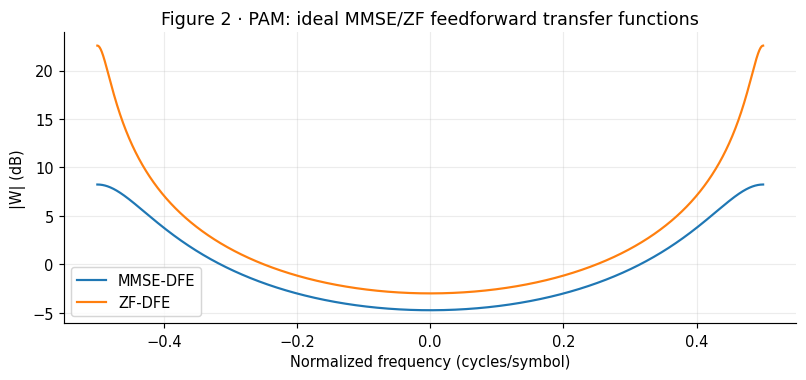

In [7]:
fig, ax = plt.subplots()
for label, equalizer in (("MMSE-DFE", pam_mmse), ("ZF-DFE", pam_zf)):
  omega, response = equalizer.frequencyResponse()
  ax.plot(omega / (2 * np.pi), 20 * np.log10(abs(response)), label=label)
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="|W| (dB)",
       title="Figure 2 · PAM: ideal MMSE/ZF feedforward transfer functions")
ax.legend()
plt.show()

## 4. Example 3.6.2 — QAM-DFE

### 4.1 Complex three-tap channel — Eq. (3.279)

Cioffi's complex-baseband QAM channel, with $T=1$, is

$$
\boxed{h_0=-\frac12,\quad h_1=1+\frac j4,\quad h_2=-\frac j2}.
$$

Channel energy:

$$
\begin{aligned}
\|h\|^2
&=\left|-\frac12\right|^2+\left|1+\frac j4\right|^2+\left|-\frac j2\right|^2\\
&=\frac14+\left(1+\frac1{16}\right)+\frac14
=\boxed{1.5625}.
\end{aligned}
$$

**Per-real-dimension convention:** QAM symbols are chosen from $\{\pm1\pm j\}$, so $\mathbb E[|x_k|^2]=2$, while each real I/Q dimension has $\bar E_x=1$. With $SNR_{\rm MFB}=10$:

$$\frac{N_0}{2}=\frac{1\times1.5625}{10}=\boxed{0.15625}.$$

The lag-$1$ and lag-$2$ complex autocorrelation coefficients must use the proper conjugates:

$$
\begin{aligned}
r_{hh}[0]&=|h_0|^2+|h_1|^2+|h_2|^2=1.5625,\\
r_{hh}[1]&=h_1h_0^*+h_2h_1^*=-0.625(1+j),\\
r_{hh}[2]&=h_2h_0^*=+0.25j,\\
r_{hh}[-1]&=r_{hh}[1]^*=-0.625(1-j),\\
r_{hh}[-2]&=r_{hh}[2]^*=-0.25j.
\end{aligned}
$$

Therefore:

$$
\boxed{
Q(D)=\frac{-0.25jD^{-2}-0.625(1-j)D^{-1}+1.5625
-0.625(1+j)D+0.25jD^2}{1.5625}
}.
$$

Equivalently:

$$Q(D)=1-0.4(1+j)D-0.4(1-j)D^{-1}+0.16jD^2-0.16jD^{-2}.$$

||h||^2 = 1.562500000, ||h|| = 1.250000000, N0/2 = 0.156250000


,Lag / degree,complex q[m]
0,-2,0.00000000 -0.16000000j
1,-1,-0.40000000 +0.40000000j
2,0,1.00000000
3,1,-0.40000000 -0.40000000j
4,2,0.00000000 +0.16000000j


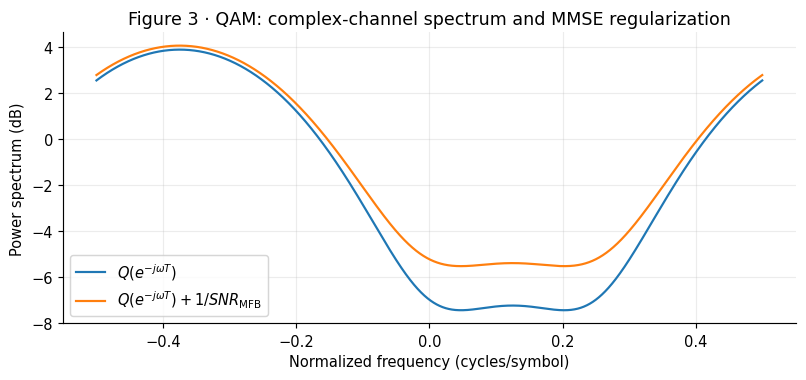

In [8]:
qam_h = np.array([-0.5, 1.0 + 0.25j, -0.5j], dtype=np.complex128)
qam_constellation = np.array([-1-1j, -1+1j, 1-1j, 1+1j], dtype=np.complex128)
qam_mmse, qam_zf = buildDfePair(qam_h, qam_constellation)
qam_energy = float(np.vdot(qam_h, qam_h).real)
qam_noise_var = SYMBOL_ENERGY_PER_REAL * qam_energy / SNR_MFB

print(f"||h||^2 = {qam_energy:.9f}, ||h|| = {np.sqrt(qam_energy):.9f}, N0/2 = {qam_noise_var:.9f}")
display(coefficientTable(qam_mmse.q_index, qam_mmse.q, "complex q[m]"))
assert np.isclose(qam_energy, 1.5625)
assert np.allclose(qam_mmse.q, np.conj(qam_mmse.q[::-1]), atol=1e-12)
assert np.isclose(qam_mmse.q[qam_mmse.q_index == 1][0], -0.4 - 0.4j)
assert np.isclose(qam_mmse.q[qam_mmse.q_index == 2][0], +0.16j)

qam_q_freq = np.fft.fftshift(qam_mmse._q_bins)
fig, ax = plt.subplots()
ax.plot(freq, 10 * np.log10(qam_q_freq), label=r"$Q(e^{-j\omega T})$")
ax.plot(freq, 10 * np.log10(qam_q_freq + 1 / SNR_MFB),
        label=r"$Q(e^{-j\omega T})+1/SNR_{\rm MFB}$")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Power spectrum (dB)",
       title="Figure 3 · QAM: complex-channel spectrum and MMSE regularization")
ax.legend()
plt.show()

### 4.2 MMSE spectral factor and conjugate-reciprocal roots — Eq. (3.280)–(3.283)

First add $1/SNR_{\rm MFB}=0.1$ to the constant term:

$$
\begin{aligned}
Q(D)+\frac1{SNR_{\rm MFB}}=
&-0.16jD^{-2}-0.4(1-j)D^{-1}\\
&+1.1-0.4(1+j)D+0.16jD^2.
\end{aligned}
$$

Let

$$
G(D)=1+g_1D+g_2D^2,\qquad
Q(D)+\frac1{SNR_{\rm MFB}}=\gamma_0G(D)G^\sharp(D).
$$

Coefficient matching gives:

$$
\begin{aligned}
1.1&=\gamma_0(1+|g_1|^2+|g_2|^2),\\
-0.4(1+j)&=\gamma_0(g_1+g_2g_1^*),\\
0.16j&=\gamma_0 g_2.
\end{aligned}
$$

The notebook does not hard-code the complex roots as predefined constants. `MMSEDFE.fromChannel` uses **complex-cepstrum spectral factorization**, and we independently verify that both zeros of $G(z)=z^2+g_1z+g_2$ satisfy $|z|<1$:

$$
\boxed{G(D)\approx1-0.4226005(1+j)D+0.2034277jD^2},\qquad
\boxed{\gamma_0\approx0.7865203}.
$$

On the unit circle, $G^\sharp(D)=1+g_1^*D^{-1}+g_2^*D^{-2}$; **complex conjugation must not be omitted**.

In [9]:
qam_g = qam_mmse.canonical_factor
qam_g_roots_z = np.roots(qam_g)      # roots of z^2 + g1*z + g2
qam_g_roots_d = np.roots(qam_g[::-1])

display(pd.DataFrame({
  "z-plane zero": [complexText(z, 9) for z in qam_g_roots_z],
  "|z|": np.abs(qam_g_roots_z),
  "D-plane root": [complexText(d, 9) for d in qam_g_roots_d],
  "minimum-phase?": np.abs(qam_g_roots_z) < 1,
}).round(9))

print(f"gamma_0 = {qam_mmse.gamma0:.10f}")
print("G(D) coefficients =", [complexText(c, 10) for c in qam_g])
print(f"Coefficient match, lag 0: {qam_mmse.gamma0 * np.sum(abs(qam_g)**2):.10f} (expected 1.1)")
print(f"Coefficient match, lag 1: {complexText(qam_mmse.gamma0 * (qam_g[1] + qam_g[2] * qam_g[1].conjugate()))}")
print(f"Coefficient match, lag 2: {complexText(qam_mmse.gamma0 * qam_g[2])}")
print(f"Max spectral reconstruction difference = {checkCanonical(qam_mmse):.3e}")
assert np.all(np.abs(qam_g_roots_z) < 1.0)
assert checkCanonical(qam_mmse) < 1e-10
assert np.isclose(qam_mmse.gamma0 * qam_g[2], 0.16j, atol=1e-9)

,z-plane zero,|z|,D-plane root,minimum-phase?
0,0.450185246 -0.027584709j,0.45103,-0.135599593 -2.212999056j,True
1,-0.027584709 +0.450185246j,0.45103,2.212999056 +0.135599593j,True


gamma_0 = 0.7865203315
G(D) coefficients = ['1.0000000000', '-0.4226005366 -0.4226005366j', '0.0000000000 +0.2034276720j']
Coefficient match, lag 0: 1.1000000000 (expected 1.1)
Coefficient match, lag 1: -0.40000000 -0.40000000j
Coefficient match, lag 2: 0.00000000 +0.16000000j
Max spectral reconstruction difference = 2.665e-15


### 4.3 MMSE feedforward, feedback, bias and SNR — Eq. (3.282)–(3.285)

Substitute the spectral factor into the MMSE-DFE design equations:

$$
\begin{aligned}
B_{\rm MMSE-DFE}(D)&=G(D)
\approx1-0.4226005(1+j)D+0.2034277jD^2,\\
1-B_{\rm MMSE-DFE}(D)&\approx0.4226005(1+j)D-0.2034277jD^2,\\
W_{\rm MMSE-DFE}(D)&=\frac{1}{1.25\gamma_0G^\sharp(D)}\\
&\approx\frac{1.01716}{1-0.4226005(1-j)D^{-1}-0.2034277jD^{-2}}.
\end{aligned}
$$

The receiver output under ideal correct feedback is therefore

$$
z'_k=z_k+0.4226005(1+j)\hat x_{k-1}-0.2034277j\hat x_{k-2}.
$$

Its theoretical MSE and unbiased SNR are:

$$
\boxed{\sigma_{\rm MMSE-DFE}^2=\frac{0.15625}{1.5625\gamma_0}=\frac{0.1}{\gamma_0}},
\quad
\boxed{SNR_{\rm MMSE-DFE,U}=\gamma_0\,10-1}.
$$

**QAM normalization:** Divide the simulated $|x_k-z'_k|^2$ by 2 when comparing with the theoretical MSE expressed per real dimension.

In [10]:
print(f"MMSE W(D) numerator = {1 / (qam_mmse.h_norm * qam_mmse.gamma0):.9f}")
print("MMSE B(D) polynomial=", [complexText(c) for c in qam_mmse.feedback_polynomial])
print("MMSE actual feedback=", [complexText(c) for c in qam_mmse.actualFeedbackTaps(unbiased=False)])
print(f"alpha = {qam_mmse.alpha():.9f}")
print("Unbiased feedback G_U=", [complexText(c) for c in qam_mmse.unbiasedFeedbackPolynomial()])
print(f"MMSE MSE per real dimension = {qam_mmse.idealMse():.9f}")
print(f"Unbiased SNR = {qam_mmse.unbiasedSnr():.9f} = {positiveDb(qam_mmse.unbiasedSnr()):.6f} dB")
assert np.isclose(qam_mmse.unbiasedSnr(), qam_mmse.gamma0 * SNR_MFB - 1.0)

MMSE W(D) numerator = 1.017138360
MMSE B(D) polynomial= ['1.00000000', '-0.42260054 -0.42260054j', '0.00000000 +0.20342767j']
MMSE actual feedback= ['0.42260054 +0.42260054j', '-0.00000000 -0.20342767j']
alpha = 0.872857705
Unbiased feedback G_U= ['1.00000000', '-0.48415742 -0.48415742j', '0.00000000 +0.23305938j']
MMSE MSE per real dimension = 0.127142295
Unbiased SNR = 6.865203315 = 8.366534 dB


### 4.4 ZF factorization — Eq. (3.286)–(3.291)

ZF-DFE factorizes the unregularized $Q(D)$ and selects the minimum-phase factor with two zeros:

$$
\boxed{P_c(D)=(1-0.5D)(1-0.5jD)=1-0.5(1+j)D+0.25jD^2}.
$$

The two $z$-plane zeros are at $z=0.5$ and $z=0.5j$. Since $q_0=1$:

$$
1=\eta_0\bigl(1+|-0.5(1+j)|^2+|0.25j|^2\bigr)
=\eta_0(1+0.5+0.0625),
$$

Consequently,

$$\boxed{\eta_0=\frac1{1.5625}=0.64}.$$

The ZF filters, output noise variance, and detection SNR are:

$$
\begin{aligned}
W_{\rm ZF-DFE}(D)
&=\frac1{1.25(0.64)P_c^\sharp(D)}
=\boxed{\frac{1.25}{1-0.5(1-j)D^{-1}-0.25jD^{-2}}},\\
1-B_{\rm ZF-DFE}(D)&=\boxed{0.5(1+j)D-0.25jD^2},\\
\sigma_{\rm ZF-DFE}^2&=\frac{0.15625}{1.5625(0.64)}=0.15625,\\
SNR_{\rm ZF-DFE}&=\frac{1}{0.15625}=6.4.
\end{aligned}
$$

In [11]:
print("ZF P_c(D) =", [complexText(c, 9) for c in qam_zf.canonical_factor])
print(f"ZF eta_0 = {qam_zf.eta0:.10f} (expected 0.6400000000)")
print(f"ZF W(D) numerator = {1 / (qam_zf.h_norm * qam_zf.eta0):.9f}")
print("ZF feedback 1-P_c =", [complexText(c) for c in qam_zf.actualFeedbackTaps()])
print(f"ZF output noise variance = {qam_zf.idealOutputNoiseVariance():.9f}")
print(f"ZF SNR = {qam_zf.unbiasedSnr():.9f} = {positiveDb(qam_zf.unbiasedSnr()):.6f} dB")
assert np.allclose(qam_zf.canonical_factor, [1, -0.5-0.5j, 0.25j], atol=1e-9)
assert np.isclose(qam_zf.eta0, 0.64, atol=1e-10)
assert checkCanonical(qam_zf) < 1e-10

ZF P_c(D) = ['1.000000000', '-0.500000000 -0.500000000j', '-0.000000000 +0.250000000j']
ZF eta_0 = 0.6400000000 (expected 0.6400000000)
ZF W(D) numerator = 1.250000000
ZF feedback 1-P_c = ['0.50000000 +0.50000000j', '0.00000000 -0.25000000j']
ZF output noise variance = 0.156250000
ZF SNR = 6.400000000 = 8.061800 dB


### 4.5 QAM frequency-domain comparison

MMSE regularization changes the canonical-factor coefficients, whereas ZF uses the minimum-phase spectral factorization of the original $Q(D)$. The following figure compares their feedforward-filter magnitude responses.

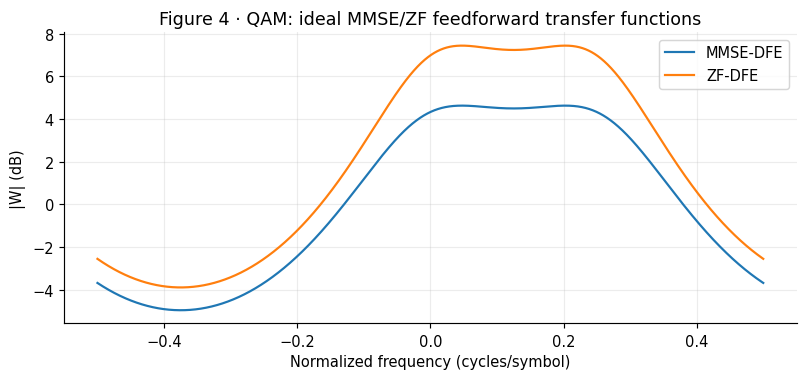

In [12]:
fig, ax = plt.subplots()
for label, equalizer in (("MMSE-DFE", qam_mmse), ("ZF-DFE", qam_zf)):
  omega, response = equalizer.frequencyResponse()
  ax.plot(omega / (2 * np.pi), 20 * np.log10(abs(response)), label=label)
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="|W| (dB)",
       title="Figure 4 · QAM: ideal MMSE/ZF feedforward transfer functions")
ax.legend()
plt.show()

## 5. Whitening and bias-removal identities

### 5.1 Why is the MMSE total estimation error white while the filtered noise need not be white?

For MMSE-DFE, define the correct-decision estimation error as

$$E(D)=B(D)X(D)-W(D)Y(D).$$

Substituting the matched-filter channel model $Y(D)=\|h\|Q(D)X(D)+N(D)$ gives

$$E(D)=\underbrace{\left[B(D)-\|h\|W(D)Q(D)\right]X(D)}_{\text{signal-dependent term}}
-\underbrace{W(D)N(D)}_{\text{filtered noise}}.$$

When symbols and noise are uncorrelated, the total error PSD is the sum of the two contributions:

$$
\bar R_{ee}(D)=
\bar E_x\left|B(D)-\|h\|W(D)Q(D)\right|^2
+\frac{N_0}{2}Q(D)|W(D)|^2
$$

(The magnitudes above are evaluated on the unit circle.) Canonical factorization guarantees

$$\boxed{\bar R_{ee}(D)=\frac{N_0/2}{\|h\|^2\gamma_0}},$$

which is constant. However, the filtered-noise contribution $\bar R_{n'n'}(D)$ generally varies with frequency. For ZF-DFE, the signal-dependent contribution vanishes under ideal conditions, so **the filtered noise itself is white**:

$$\boxed{\bar R_{n'n'}^{\rm ZF}(D)=\frac{N_0/2}{\|h\|^2\eta_0}}.$$

The following code reconstructs both PSDs directly from the ideal model frequency responses, checking each frequency bin rather than comparing only their integrated powers.

In [13]:
def idealErrorSpectra(equalizer, symbol_energy_per_real=1.0):
  q_freq = equalizer._q_bins
  w_freq = equalizer._w_bins
  b_freq = fftOfIndexedTaps(
    equalizer.canonical_factor, np.arange(len(equalizer.canonical_factor)), equalizer.n_fft,
  )
  noise_var = symbol_energy_per_real * equalizer.h_norm**2 / equalizer.snr_mfb
  signal_error = symbol_energy_per_real * abs(b_freq - equalizer.h_norm * w_freq * q_freq)**2
  filtered_noise = noise_var * q_freq * abs(w_freq)**2
  return signal_error, filtered_noise, signal_error + filtered_noise

for label, mmse, zf in (("PAM", pam_mmse, pam_zf), ("QAM", qam_mmse, qam_zf)):
  mmse_signal_psd, mmse_noise_psd, mmse_total_psd = idealErrorSpectra(mmse)
  zf_signal_psd, zf_noise_psd, zf_total_psd = idealErrorSpectra(zf)
  mmse_flatness = np.max(abs(mmse_total_psd - mmse.idealMse()))
  zf_flatness = np.max(abs(zf_noise_psd - zf.idealMse()))
  print(f"{label}: MMSE total-error PSD max residual = {mmse_flatness:.3e}; "
        f"ZF filtered-noise PSD max residual = {zf_flatness:.3e}")
  print(f"    MMSE filtered noise PSD range: {mmse_noise_psd.min():.7f} ... {mmse_noise_psd.max():.7f}")
  print(f"    ZF signal-dependent error PSD maximum: {zf_signal_psd.max():.3e}")
  assert mmse_flatness < 1e-9
  assert zf_flatness < 1e-9
  assert zf_signal_psd.max() < 1e-9

PAM: MMSE total-error PSD max residual = 5.551e-16; ZF filtered-noise PSD max residual = 5.829e-16
    MMSE filtered noise PSD range: 0.0066690 ... 0.1212966
    ZF signal-dependent error PSD maximum: 2.845e-29
QAM: MMSE total-error PSD max residual = 3.331e-16; ZF filtered-noise PSD max residual = 3.608e-16
    MMSE filtered noise PSD range: 0.0817343 ... 0.1221590
    ZF signal-dependent error PSD maximum: 4.006e-30


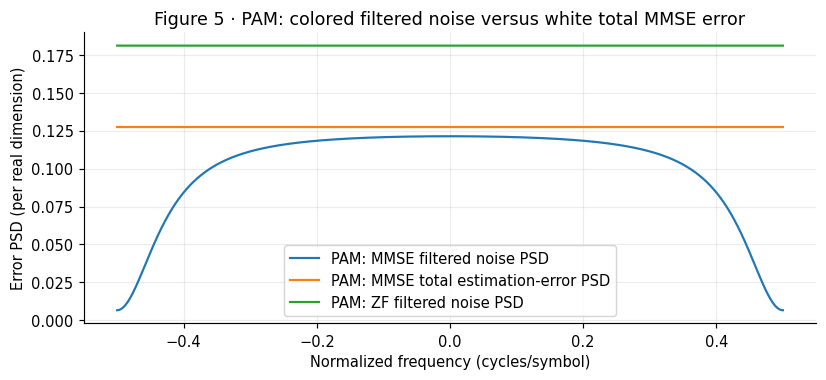

In [14]:
fig, ax = plt.subplots()
_, pam_noise, pam_total = idealErrorSpectra(pam_mmse)
_, pam_zf_noise, _ = idealErrorSpectra(pam_zf)
ax.plot(freq, np.fft.fftshift(pam_noise), label="PAM: MMSE filtered noise PSD")
ax.plot(freq, np.fft.fftshift(pam_total), label="PAM: MMSE total estimation-error PSD")
ax.plot(freq, np.fft.fftshift(pam_zf_noise), label="PAM: ZF filtered noise PSD")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Error PSD (per real dimension)",
       title="Figure 5 · PAM: colored filtered noise versus white total MMSE error")
ax.legend()
plt.show()

### 5.2 Biased and unbiased MMSE receiver structures

The unbiased scaling in Cioffi Figure 3.37 is

$$\alpha=1-\frac1{\gamma_0SNR_{\rm MFB}},\qquad
G_U(D)=1+\frac{G(D)-1}{\alpha}.$$

For any **identical feedback history**, even if some decisions are incorrect, the following identity holds:

$$
\begin{aligned}
Z'_U(D)&=\frac{Z(D)}{\alpha}+\left[1-G_U(D)\right]\hat X(D)\\
&=\frac{Z(D)+[1-G(D)]\hat X(D)}{\alpha}=\boxed{\frac{Z'(D)}{\alpha}}.
\end{aligned}
$$

The code uses `ideal_feedback=True` to ensure identical feedback histories in the biased and unbiased runs, then compares their outputs sample by sample. In ZF-DFE, $\alpha=1$, so the two forms coincide.

In [15]:
rng = np.random.default_rng(RNG_SEED)
for label, equalizer, constellation in (
  ("PAM", pam_mmse, pam_constellation),
  ("QAM", qam_mmse, qam_constellation),
):
  symbols = rng.choice(constellation, size=2048)
  received = equalizer.matchedFilterOutput(symbols)
  biased = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=False)
  unbiased = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=True)
  difference = np.max(abs(unbiased.decision_input - biased.decision_input / equalizer.alpha()))
  print(f"{label}: max |z'_U - z'/alpha| = {difference:.3e}, alpha = {equalizer.alpha():.9f}")
  assert difference < 1e-10

PAM: max |z'_U - z'/alpha| = 2.220e-16, alpha = 0.872621752
QAM: max |z'_U - z'/alpha| = 4.965e-16, alpha = 0.872857705


## 6. Monte Carlo: correct feedback versus decision-directed

To match the Cioffi matched-filter model, **independent white noise must not be added directly to the matched-filter samples**. Instead, the output noise must satisfy:

$$\bar R_{nn}(D)=\frac{N_0}{2}Q(D).$$

If $r_{hh}[m]$ is the channel autocorrelation, generate unit-variance white noise $v_k$ and form

$$n_k=\sqrt{\frac{N_0/2}{\|h\|^2}}\sum_mh_m v_{k-m}.$$

For QAM, the real and imaginary components of $v_k$ each have variance 1, so $\mathbb E[|v_k|^2]=2$. Divide the resulting complex MSE by 2 to recover the per-real-dimension convention.

Compare two feedback assumptions:

- **Correct-decision benchmark**：`ideal_feedback=True` uses the actual past transmitted symbols to validate the theoretical MSE (this is not a practical blind receiver).
- **Decision-directed**：Teacher forcing supplies correct symbols to the feedback history for the first 384 symbols; subsequent symbols use hard decisions. The filter **does not perform LMS/RLS adaptation**.

To avoid finite-record boundary transients from the noncausal feedforward filter, the first and last 384 symbols are excluded from statistics.

In [16]:
def randomSymbols(rng, constellation, n_symbols):
  return rng.choice(constellation, size=n_symbols).astype(np.complex128)


def matchedFilterNoise(rng, h, n_symbols, noise_var_per_real, complex_channel):
  """Synthesize matched-filter colored noise; QAM I/Q each has real variance noise_var_per_real."""
  white = rng.standard_normal(n_symbols + len(h) - 1)
  if complex_channel:
    white = white + 1j * rng.standard_normal(n_symbols + len(h) - 1)
  raw = np.convolve(white, h, mode="full")[:n_symbols]
  return raw * np.sqrt(noise_var_per_real / np.vdot(h, h).real)


def evaluateReceiver(equalizer, received, symbols, guard, real_dimensions):
  correct = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=True)
  directed = equalizer.apply(received, known_symbols=symbols, training_samples=guard, unbiased=True)
  valid = slice(guard, len(symbols) - guard)
  return {
    "correct_feedback_mse": float(np.mean(abs(symbols[valid] - correct.decision_input[valid])**2)
                                  / real_dimensions),
    "decision_directed_mse": float(np.mean(abs(symbols[valid] - directed.decision_input[valid])**2)
                                    / real_dimensions),
    "correct_feedback_ser": float(np.mean(correct.decisions[valid] != symbols[valid])),
    "decision_directed_ser": float(np.mean(directed.decisions[valid] != symbols[valid])),
    "correct_output": correct,
    "directed_output": directed,
  }

In [17]:
N_SYMBOLS = 24000
GUARD = 384
simulation_rows = []
simulation_results = {}
rng = np.random.default_rng(RNG_SEED)

for label, h, constellation, mmse, zf, n_real in (
  ("PAM", pam_h, pam_constellation, pam_mmse, pam_zf, 1),
  ("QAM", qam_h, qam_constellation, qam_mmse, qam_zf, 2),
):
  symbols = randomSymbols(rng, constellation, N_SYMBOLS)
  noise_var = float(np.vdot(h, h).real / SNR_MFB)
  colored_noise = matchedFilterNoise(rng, h, N_SYMBOLS, noise_var, label == "QAM")
  received = mmse.matchedFilterOutput(symbols, noise=colored_noise)

  for criterion, equalizer in (("MMSE", mmse), ("ZF", zf)):
    metrics = evaluateReceiver(equalizer, received, symbols, GUARD, n_real)
    simulation_results[(label, criterion)] = metrics
    theoretical_unbiased_mse = SYMBOL_ENERGY_PER_REAL / equalizer.unbiasedSnr()
    simulation_rows.append({
      "Channel": label,
      "DFE": criterion,
      "Theoretical unbiased MSE": theoretical_unbiased_mse,
      "Correct-feedback MSE": metrics["correct_feedback_mse"],
      "Decision-directed MSE": metrics["decision_directed_mse"],
      "Correct-feedback SER": metrics["correct_feedback_ser"],
      "Decision-directed SER": metrics["decision_directed_ser"],
    })
    relative_difference = abs(metrics["correct_feedback_mse"] - theoretical_unbiased_mse)
    assert relative_difference / theoretical_unbiased_mse < 0.10

simulation_table = pd.DataFrame(simulation_rows)
display(simulation_table.round(6))
print(f"Evaluated {N_SYMBOLS - 2 * GUARD} central symbol decisions per channel/method.")

,Channel,DFE,Theoretical unbiased MSE,Correct-feedback MSE,Decision-directed MSE,Correct-feedback SER,Decision-directed SER
0,PAM,MMSE,0.145972,0.146503,0.171085,0.004950,0.013128
1,PAM,ZF,0.181000,0.182088,0.238513,0.009642,0.017949
2,QAM,MMSE,0.145662,0.146136,0.156622,0.008394,0.014162
3,QAM,ZF,0.156250,0.157258,0.175167,0.011751,0.018810


Evaluated 23232 central symbol decisions per channel/method.


### 6.1 How to interpret Monte Carlo MSE

The optimal MMSE error variance derived in §3.6 refers to the **biased estimation error**:

$$\sigma_{\rm MMSE-DFE}^2=\frac{\bar E_x}{\gamma_0SNR_{\rm MFB}}.$$

In this simulation, `decision_input` uses `unbiased=True`, so the relevant variance is instead

$$\boxed{\sigma_{\rm MMSE-DFE,U}^2=\frac{\bar E_x}{\gamma_0SNR_{\rm MFB}-1}}.$$

For ZF-DFE:

$$\boxed{\sigma_{\rm ZF-DFE}^2=\frac{\bar E_x}{\eta_0SNR_{\rm MFB}}}.$$

Accordingly, `Theoretical unbiased MSE` is computed as `1 / unbiasedSnr()`, not taken directly from the class method `idealMse()` (which returns the biased MSE for MMSE-DFE). With a sufficiently long finite feedforward filter and transient removal, the correct-feedback MSE should approach theory; decision-directed MSE may additionally suffer from **error propagation**.

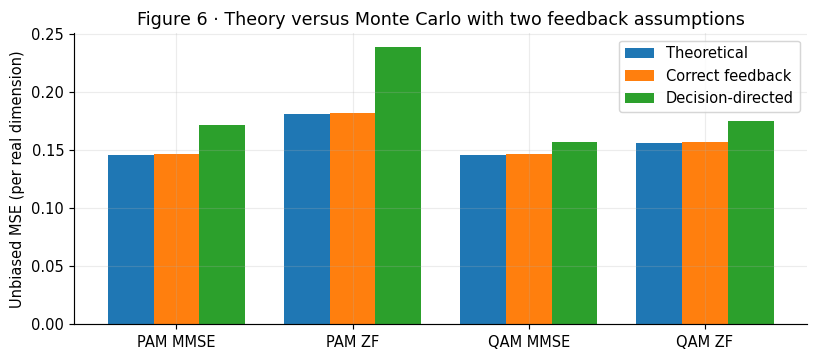

In [18]:
fig, ax = plt.subplots()
method_names = [f"{r['Channel']} {r['DFE']}" for r in simulation_rows]
positions = np.arange(len(method_names), dtype=float)
bar_width = 0.26
ax.bar(positions - bar_width, simulation_table["Theoretical unbiased MSE"],
       width=bar_width, label="Theoretical")
ax.bar(positions, simulation_table["Correct-feedback MSE"], width=bar_width, label="Correct feedback")
ax.bar(positions + bar_width, simulation_table["Decision-directed MSE"],
       width=bar_width, label="Decision-directed")
ax.set_xticks(positions, method_names)
ax.set(ylabel="Unbiased MSE (per real dimension)",
       title="Figure 6 · Theory versus Monte Carlo with two feedback assumptions")
ax.legend()
plt.show()

## 7. Finite feedforward approximation

The $W(D)$ response derived in Cioffi §3.6.4 generally has an **infinite anticausal tail**. The existing `canonical_dfe.py` samples the ideal frequency response $W(e^{-j\omega T})$ and extracts $N_{\rm FF}$ FIR taps:

$$W_{\rm finite}(D)=\sum_{m=1-N_{\rm FF}}^{0}w_mD^m.$$

Here we calculate the exact second-order MSE of the finite FIR approximation instead of relying on Monte Carlo sampling error. Under correct feedback:

$$
Z'(D)=\left[\|h\|W_{\rm finite}(D)Q(D)+1-B(D)\right]X(D)+W_{\rm finite}(D)N(D).
$$

When the unbiased output is defined as $Z'_U=Z'/\alpha$, the resulting error variance is

$$
\boxed{
\begin{aligned}
\sigma_{\rm finite,U}^2=
&\frac{\bar E_x}{2\pi}\int_{-\pi}^{\pi}
\left|1-\frac{\|h\|W_{\rm finite}(e^{-j\theta})Q(e^{-j\theta})+1-B(e^{-j\theta})}
{\alpha}\right|^2d\theta\\
&+\frac{N_0/2}{2\pi}\int_{-\pi}^{\pi}
Q(e^{-j\theta})\left|\frac{W_{\rm finite}(e^{-j\theta})}{\alpha}\right|^2d\theta.
\end{aligned}
}
$$

This measures the performance of an **ideal canonical factor combined with a truncated feedforward FIR**; it is not the jointly optimized finite FF/FB design of Chapter 3.7.

In [19]:
def finiteUnbiasedMse(equalizer):
  w_freq = fftOfIndexedTaps(equalizer.w, equalizer.w_index, equalizer.n_fft)
  b_freq = fftOfIndexedTaps(
    equalizer.feedback_polynomial,
    np.arange(len(equalizer.feedback_polynomial)),
    equalizer.n_fft,
  )
  alpha = equalizer.alpha()
  cascade = (equalizer.h_norm * w_freq * equalizer._q_bins + 1 - b_freq) / alpha
  noise_var = SYMBOL_ENERGY_PER_REAL * equalizer.h_norm**2 / equalizer.snr_mfb
  return float(np.mean(SYMBOL_ENERGY_PER_REAL * abs(1 - cascade)**2 +
                       noise_var * equalizer._q_bins * abs(w_freq / alpha)**2))

finite_rows = []
for label, h, constellation in (
  ("PAM", pam_h, pam_constellation),
  ("QAM", qam_h, qam_constellation),
):
  for taps in (8, 16, 32, 64, 128, N_FF):
    for cls, criterion in ((MMSEDFE, "MMSE"), (ZFDFE, "ZF")):
      equalizer = cls.fromChannel(h, snr_mfb=SNR_MFB, n_taps=taps,
                                  n_fft=N_FFT, constellation=constellation)
      finite_rows.append({
        "Channel": label,
        "DFE": criterion,
        "FF taps": taps,
        "Finite unbiased MSE": finiteUnbiasedMse(equalizer),
        "Ideal unbiased MSE": SYMBOL_ENERGY_PER_REAL / equalizer.unbiasedSnr(),
      })
finite_table = pd.DataFrame(finite_rows)
display(finite_table.pivot_table(index=["Channel", "DFE"], columns="FF taps",
                                 values="Finite unbiased MSE").round(6))

FF taps            8         16        32        64        128       160
Channel DFE                                                             
PAM     MMSE  0.147094  0.145973  0.145972  0.145972  0.145972  0.145972
        ZF    0.549936  0.249365  0.183347  0.181003  0.181000  0.181000
QAM     MMSE  0.145673  0.145662  0.145662  0.145662  0.145662  0.145662
        ZF    0.156276  0.156250  0.156250  0.156250  0.156250  0.156250

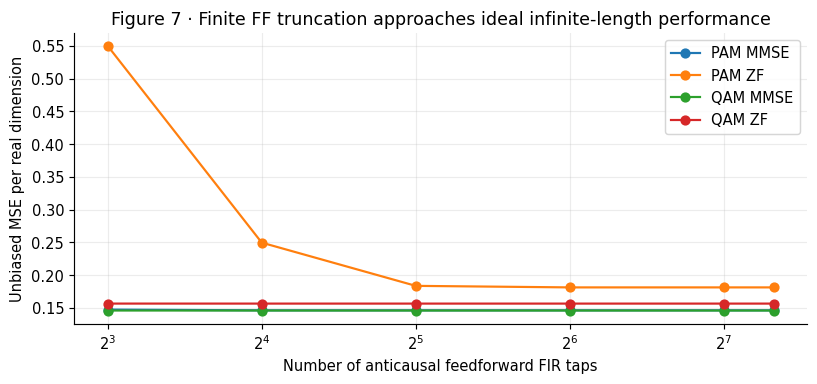

In [20]:
fig, ax = plt.subplots()
for channel_name in ("PAM", "QAM"):
  for criterion in ("MMSE", "ZF"):
    subset = finite_table[(finite_table["Channel"] == channel_name) &
                          (finite_table["DFE"] == criterion)].sort_values("FF taps")
    ax.plot(subset["FF taps"], subset["Finite unbiased MSE"], "o-",
            label=f"{channel_name} {criterion}")
ax.set(xlabel="Number of anticausal feedforward FIR taps", ylabel="Unbiased MSE per real dimension",
       title="Figure 7 · Finite FF truncation approaches ideal infinite-length performance")
ax.set_xscale("log", base=2)
ax.legend()
plt.show()

## 8. Comparative results and conclusions

### 8.1 Computing detection SNR directly from the three formulas

Continuing the comparison from §3.6.3, we retain the full frequency integrals instead of introducing a frequency-average shorthand:

$$
SNR_{\rm ZF-LE}=
\frac{SNR_{\rm MFB}}{\displaystyle\frac{T}{2\pi}
\int_{-\pi/T}^{\pi/T}\frac{1}{Q(e^{-j\omega T})}\,d\omega}.
$$

$$
SNR_{\rm ZF-DFE}=
SNR_{\rm MFB}\exp\left[\frac{T}{2\pi}
\int_{-\pi/T}^{\pi/T}\ln Q(e^{-j\omega T})\,d\omega\right].
$$

$$
SNR_{\rm MMSE-DFE,U}=
\exp\left[\frac{T}{2\pi}\int_{-\pi/T}^{\pi/T}
\ln\left(1+SNR_{\rm MFB}Q(e^{-j\omega T})\right)d\omega\right]-1.
$$

Under the ideal assumptions:

$$\boxed{SNR_{\rm ZF-LE}\le SNR_{\rm ZF-DFE}\le SNR_{\rm MMSE-DFE,U}\le SNR_{\rm MFB}}.$$

The code evaluates these three frequency-domain expressions by numerical quadrature on a dense frequency grid and compares them with the results returned by `MMSEDFE` and `ZFDFE`.

In [21]:
comparison_rows = []
for name, mmse, zf in (("PAM", pam_mmse, pam_zf), ("QAM", qam_mmse, qam_zf)):
  q_bins = mmse._q_bins
  snr_zf_le = SNR_MFB / float(np.mean(1.0 / q_bins))
  snr_zf_dfe_integral = SNR_MFB * float(np.exp(np.mean(np.log(q_bins))))
  snr_mmse_dfe_integral = float(np.exp(np.mean(np.log(1.0 + SNR_MFB * q_bins))) - 1.0)
  assert snr_zf_le <= snr_zf_dfe_integral + 1e-11
  assert snr_zf_dfe_integral <= snr_mmse_dfe_integral + 1e-11
  assert snr_mmse_dfe_integral <= SNR_MFB + 1e-11
  assert np.isclose(zf.unbiasedSnr(), snr_zf_dfe_integral, atol=1e-10)
  assert np.isclose(mmse.unbiasedSnr(), snr_mmse_dfe_integral, atol=1e-10)
  comparison_rows.append({
    "Channel": name,
    "ZF-LE (dB)": positiveDb(snr_zf_le),
    "ZF-DFE (dB)": positiveDb(snr_zf_dfe_integral),
    "MMSE-DFE,U (dB)": positiveDb(snr_mmse_dfe_integral),
    "MFB (dB)": positiveDb(SNR_MFB),
  })
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(6))

,Channel,ZF-LE (dB),ZF-DFE (dB),"MMSE-DFE,U (dB)",MFB (dB)
0,PAM,0.210750,7.423214,8.357308,10.0
1,QAM,6.106602,8.061800,8.366534,10.0


### 8.2 Reproducibility checks

All assertions pass, providing numerical checks of the following properties:

1. The PAM values $\gamma_0\approx0.785063$ and $\eta_0=1/1.81$, together with the roots used for the minimum-phase selection.
2. Hermitian symmetry of the complex QAM autocorrelation and $\eta_0=0.64$.
3. MMSE/ZF spectral reconstruction, including the complex $D^2$ coefficient.
4. Whiteness of the MMSE total-error PSD and of the ZF filtered-noise PSD.
5. Equivalence of MMSE biased/unbiased outputs under $Z'_U=Z'/\alpha$.
6. Consistency between Monte Carlo correct-feedback unbiased MSE and the Chapter 3.6 theoretical SNR.
7. The performance gap between finite anticausal feedforward approximations and ideal infinite-length feedforward filters.

**Implementation boundary:** The DFE assumes a known channel and uses an offline approximation of the noncausal feedforward response. It does not implement channel estimation, LMS/RLS coefficient updates, or a hardware decision delay. Incorrect feedback decisions may cause error propagation, reducing performance relative to the ideal SNR. Before targeting RTL, study the jointly optimal finite-length FF/FB design in Chapter 3.7.

**Original references:** Cioffi, *Digital Communications*, Chapter 3, §3.6.4, Examples Revisited. The accompanying `adsp/equalization/canonical_dfe.py` documents the reference-model API.

In [22]:
print("REPRODUCTION PASSED")
print("  PAM MMSE-DFE,U:  ", f"{positiveDb(pam_mmse.unbiasedSnr()):.6f} dB")
print("  PAM ZF-DFE:      ", f"{positiveDb(pam_zf.unbiasedSnr()):.6f} dB")
print("  QAM MMSE-DFE,U:  ", f"{positiveDb(qam_mmse.unbiasedSnr()):.6f} dB")
print("  QAM ZF-DFE:      ", f"{positiveDb(qam_zf.unbiasedSnr()):.6f} dB")
print(f"  Canonical reconstruction: {max(checkCanonical(eq) for eq in (pam_mmse,pam_zf,qam_mmse,qam_zf)):.3e}")
print("  Reference-model classes: adsp.equalization.canonical_dfe.MMSEDFE / ZFDFE")

REPRODUCTION PASSED
  PAM MMSE-DFE,U:   8.357308 dB
  PAM ZF-DFE:       7.423214 dB
  QAM MMSE-DFE,U:   8.366534 dB
  QAM ZF-DFE:       8.061800 dB
  Canonical reconstruction: 2.665e-15
  Reference-model classes: adsp.equalization.canonical_dfe.MMSEDFE / ZFDFE
